In [23]:
from dotenv import load_dotenv

In [24]:
load_dotenv()


True

In [25]:
from langchain_openai import ChatOpenAI
llm_client = ChatOpenAI(
    model_name="gpt-5.4-mini",
    temperature=1)


response = llm_client.invoke("tell me about npci in 2 bulletien points")
response

AIMessage(content='- **NPCI (National Payments Corporation of India)** is the umbrella organization that runs many of India’s retail payment systems, such as **UPI, RuPay, IMPS, and AePS**.  \n- It helps make **digital payments fast, secure, and widely available** across banks and payment apps in India.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 17, 'total_tokens': 86, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini-2026-03-17', 'system_fingerprint': None, 'id': 'chatcmpl-Edrh6LUJEXvzbAIFLRnM9JzOalTEJ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18141-416b-70c5-bfcd-d4051

In [4]:
## creating a agent

Basic agent created successfully!


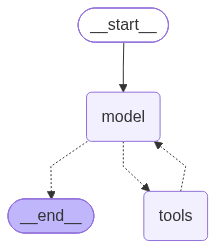

In [26]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_openai import ChatOpenAI

# Initialize the model
model = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Define simple tools
@tool
def calculator(expression: str) -> str:
    """Perform basic mathematical calculations."""
    try:
        result = eval(expression)
        return f"Result: {result}"
    except Exception as e:
        return f"Error: {str(e)}"

@tool
def get_time() -> str:
    """Get the current time."""
    from datetime import datetime
    return f"Current time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"

# Create the agent with tools
basic_agent = create_agent(
    model=model,
    tools=[calculator, get_time],
    system_prompt="You are a helpful assistant that can perform calculations and tell time."
)

print("Basic agent created successfully!")
basic_agent

In [27]:
# Test the basic agent
result = basic_agent.invoke({
    "messages": [{"role": "user", "content": "What is 15 * 7 + 23? Also, what time is it?"}]
})

print("Agent Response:")
print(result["messages"][-1].content)

result

Agent Response:
The result of \( 15 \times 7 + 23 \) is 128. 

The current time is 12:15:10 PM.


{'messages': [HumanMessage(content='What is 15 * 7 + 23? Also, what time is it?', additional_kwargs={}, response_metadata={}, id='ff3d40eb-44cd-499e-aa58-3ef277e79978'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 85, 'total_tokens': 133, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_e329c658db', 'id': 'chatcmpl-EdrhF5S2hA4A3jHwPzjYfmxOTcYo7', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a18141-64ee-7699-b500-f0711f0d2bf0-0', tool_calls=[{'name': 'calculator', 'args': {'expression': '15 * 7 + 23'}, 'id': 'cal

In [28]:
result["messages"]

[HumanMessage(content='What is 15 * 7 + 23? Also, what time is it?', additional_kwargs={}, response_metadata={}, id='ff3d40eb-44cd-499e-aa58-3ef277e79978'),
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 85, 'total_tokens': 133, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_e329c658db', 'id': 'chatcmpl-EdrhF5S2hA4A3jHwPzjYfmxOTcYo7', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a18141-64ee-7699-b500-f0711f0d2bf0-0', tool_calls=[{'name': 'calculator', 'args': {'expression': '15 * 7 + 23'}, 'id': 'call_0HoCfzWhXkgK

In [29]:
# Method 2: Using OpenWeatherMap tool from LangChain
from langchain_community.tools.openweathermap import OpenWeatherMapQueryRun
from langchain_community.utilities.openweathermap import OpenWeatherMapAPIWrapper
from pydantic import BaseModel

# Initialize OpenWeatherMap tool with API wrapper
openweather_wrapper = OpenWeatherMapAPIWrapper()
#get_weather = OpenWeatherMapQueryRun(api_wrapper=openweather_wrapper)

# Alternative: Custom tool using OpenWeatherMap if you need more control
class WeatherInput(BaseModel):
    location: str

@tool(args_schema=WeatherInput)
def get_weather(location: str) -> str:
    """Get detailed current weather information for a specific location using OpenWeatherMap."""
    try:
        # Use the wrapper directly for more detailed response
        print(f"Fetching weather data for: {location}")
        weather_data = openweather_wrapper.run(location)
        return weather_data
    except Exception as e:
        return f"Error getting weather data: {str(e)}"

In [30]:
# Custom Tavily web search function
from tavily import TavilyClient
from langchain.tools import tool

# Initialize Tavily client
tavily_client = TavilyClient()

@tool
def web_search(query: str, max_results: int = 5) -> str:
    """Search the web using Tavily."""
    try:
        print("Performing web search...")
        response = tavily_client.search(
            query=query,
            max_results=max_results,
            include_raw_content=False
        )
        # Return the Tavily response directly for simplicity
        return response
    except Exception as e:
        return f"Error performing web search: {str(e)}"

print("Custom Tavily search tool created!")

Custom Tavily search tool created!


In [31]:
# Create agent with custom tools
tools_agent = create_agent(
    model=model,
    tools=[web_search, get_weather],
    system_prompt="You are a helpful assistant with access to web search and weather."
)

# Test the tools
result = tools_agent.invoke({
    "messages": [{
        "role": "user", 
        "content": (
            "Search for Sivaprasad valluru, get weather for Bangalore, "
            "and give me a concise combined summary."
        )
    }]
})

Performing web search...
Fetching weather data for: Bangalore
Fetching weather data for: Bangalore
Fetching weather data for: Bengaluru


In [32]:
print("Agent Response:")
print(result["messages"][-1].content)

Agent Response:
### Summary of Findings

**Sivaprasad Valluru:**
- **Professional Background:** Sivaprasad Valluru is an experienced instructor with over 20 years in the IT industry, having worked with companies like Motorola, Alcatel Lucent, and TechMahindra. He specializes in corporate training, particularly in areas such as MuleSoft and Generative AI.
- **Current Role:** He is a freelance corporate trainer based in Bengaluru, India, focusing on advanced technologies including LangChain, LlamaIndex, and various AI frameworks. He emphasizes practical training methods that help participants visualize concepts rather than relying on high-level jargon.
- **Contact Information:** He can be reached at +91 80889 10831 or via email at sivaprasad.valluru@gmail.com. More details can be found on his [LinkedIn profile](https://in.linkedin.com/in/siva-prasad-valluru-6b76b515).

**Weather in Bangalore:**
Unfortunately, I was unable to retrieve the current weather data for Bangalore due to an API i

In [33]:
# Using the predefined LangChain Tavily tool
from  langchain_tavily import TavilySearch
# Create predefined Tavily tool
tavily_tool = TavilySearch(
    max_results=3,
    search_depth="advanced",
    include_answer=True,
    include_raw_content=False,
    include_images=False
)

print("Predefined Tavily tool created!")

Predefined Tavily tool created!


In [ ]:
# Create agent with web search capabilities
web_search_agent = create_agent(
    model=model,
    tools=[tavily_tool, calculator],
    system_prompt=(
        "You are a research assistant with web search capabilities. "
        "Use web search to find current information and provide "
        "accurate, up-to-date responses."
    )
)

# Test web search
result = web_search_agent.invoke({
    "messages": [{
        "role": "user", 
        "content": "What are the latest developments in artificial intelligence in November 2025?"
    }]
})

print("Web Search Agent Response:")
print(result["messages"][-1].content)